# New Zealand Electricity Demand Forecasting
## Notebook 03 — Model Training and Evaluation

### 1. Introduction

This notebook develops machine learning models to forecast regional electricity demand in New Zealand.

The dataset contains 172,597 observations across five electricity regions, covering November 2024 to October 2026.

### Objectives

1. Load the feature-engineered electricity demand dataset.
2. Split the dataset chronologically into training and testing periods.
3. Establish a baseline forecasting model.
4. Train machine learning models to predict electricity demand.
5. Evaluate forecasting accuracy using MAE and RMSE.
6. Compare model performance and identify the most accurate approach.

### Prediction Target

**Demand (GWh)** — electricity consumption for a specified 30-minute period.

The initial forecasting task is to predict regional electricity demand using calendar information and historical demand observations available before the target period.

### Modelling Approach

The following models will be investigated:

- Seasonal naive baseline
- Linear Regression
- Random Forest Regressor
- Gradient Boosting (XGBoost)

### Evaluation Strategy

A chronological train/test split will be used.

Unlike random splitting, chronological splitting ensures that the models are trained on earlier observations and evaluated on later, unseen observations.

This better represents real-world electricity demand forecasting.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Locate the feature-engineered dataset
data_path = (
    Path.cwd().parent
    / "data"
    / "electricity_demand_features.csv"
)

# Load the dataset
df = pd.read_csv(
    data_path,
    parse_dates=["Period start"]
)

print("Dataset shape:", df.shape)

print("\nDate range:")
print("Start:", df["Period start"].min())
print("End:", df["Period start"].max())

print("\nMissing values:")
print(df.isna().sum())

display(df.head())

Dataset shape: (172597, 13)

Date range:
Start: 2024-11-08 00:00:00
End: 2026-10-31 23:30:00

Missing values:
Period start        0
Region ID           0
Region              0
Demand (GWh)        0
Hour                0
Day_of_week         0
Month               0
Weekend             0
Trading_period      0
Demand_lag_30min    0
Demand_lag_1h       0
Demand_lag_24h      0
Demand_lag_7d       0
dtype: int64


,Period start,Region ID,Region,Demand (GWh),Hour,Day_of_week,Month,Weekend,Trading_period,Demand_lag_30min,Demand_lag_1h,Demand_lag_24h,Demand_lag_7d
0,2024-11-08,CNI,Central North Island,0.370,0,4,11,0,0,0.383,0.403,0.368,0.377
1,2024-11-08,LNI,Lower North Island,0.236,0,4,11,0,0,0.251,0.269,0.244,0.246
2,2024-11-08,LSI,Lower South Island,0.424,0,4,11,0,0,0.429,0.454,0.432,0.433
3,2024-11-08,UNI,Upper North Island,0.534,0,4,11,0,0,0.564,0.600,0.526,0.541
4,2024-11-08,USI,Upper South Island,0.332,0,4,11,0,0,0.354,0.364,0.329,0.275


## 2. Chronological Train/Test Split

### 2.1 Splitting the Dataset

Electricity demand forecasting is a time series prediction problem.

Unlike traditional machine learning problems, time series observations must be split chronologically rather than randomly.

Random splitting could allow the model to learn from future observations when predicting earlier periods, producing misleading evaluation results.

For this project, the dataset will be divided into:

- **Training period:** 8 November 2024 – 30 June 2026
- **Testing period:** 1 July 2026 – 31 October 2026

The training dataset will be used to develop the forecasting models.

The testing dataset will be used to evaluate how accurately the models predict electricity demand during a later, unseen period.

### Why This Split?

The training period contains approximately 20 months of historical observations, including seasonal demand patterns.

The testing period contains four months of future observations, allowing us to evaluate model performance across winter and spring.

All five electricity regions will be included in both datasets.

**Important:** The prediction task assumes that actual historical demand is available up to 30 minutes before each forecasted period. This represents a rolling, one-step-ahead forecasting scenario.

In [2]:
# Define the chronological split date
split_date = pd.Timestamp("2026-07-01")

# Split the dataset chronologically
train_df = df[
    df["Period start"] < split_date
].copy()

test_df = df[
    df["Period start"] >= split_date
].copy()

# Display dataset sizes
print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

# Display date ranges
print("\nTraining period:")
print("Start:", train_df["Period start"].min())
print("End:", train_df["Period start"].max())

print("\nTesting period:")
print("Start:", test_df["Period start"].min())
print("End:", test_df["Period start"].max())

# Calculate proportions
print("\nDataset proportions:")
print(f"Training: {len(train_df) / len(df) * 100:.2f}%")
print(f"Testing: {len(test_df) / len(df) * 100:.2f}%")

# Verify chronological separation
assert train_df["Period start"].max() < test_df["Period start"].min()

# Verify all observations are accounted for
assert len(train_df) + len(test_df) == len(df)

print("\nChronological split validated successfully.")

Training observations: 143117
Testing observations: 29480

Training period:
Start: 2024-11-08 00:00:00
End: 2026-06-30 23:30:00

Testing period:
Start: 2026-07-01 00:00:00
End: 2026-10-31 23:30:00

Dataset proportions:
Training: 82.92%
Testing: 17.08%

Chronological split validated successfully.


## 3. Baseline Forecasting Model

### 3.1 Seasonal Naive Forecast

Before developing machine learning models, a baseline forecast will be established.

A baseline provides a benchmark for evaluating whether more complex models improve prediction accuracy.

For electricity demand forecasting, a seasonal naive approach assumes that electricity consumption at a particular time will be similar to consumption at the same time on the previous day.

For example:

- Monday at 8:00 AM is predicted using Sunday's demand at 8:00 AM.
- Tuesday at 6:30 PM is predicted using Monday's demand at 6:30 PM.

The forecast is defined as:

**Predicted demand(t) = Actual demand(t − 24 hours)**

The existing `Demand_lag_24h` feature provides these historical observations.

### Evaluation Metrics

Two metrics will be used:

**Mean Absolute Error (MAE)**

Measures the average absolute difference between predicted and actual electricity demand.

**Root Mean Squared Error (RMSE)**

Measures prediction error while penalising larger errors more heavily.

Both metrics are measured in GWh.

Lower values indicate better forecasting performance.

The baseline will be evaluated using the testing dataset only.

In [3]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Actual electricity demand
y_test = test_df["Demand (GWh)"]

# Seasonal naive prediction: demand at the same time yesterday
baseline_predictions = test_df["Demand_lag_24h"]

# Calculate evaluation metrics
baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_predictions
    )
)

# Display results
print("Seasonal Naive Baseline Results")
print("-" * 35)

print(f"MAE:  {baseline_mae:.5f} GWh")
print(f"RMSE: {baseline_rmse:.5f} GWh")

Seasonal Naive Baseline Results
-----------------------------------
MAE:  0.02843 GWh
RMSE: 0.04229 GWh


## 4. Linear Regression Model

### 4.1 Model Development

Linear Regression will be used as the first machine learning forecasting model.

Linear Regression estimates electricity demand as a weighted combination of input features.

The model will use:

**Calendar features**
- Hour
- Day_of_week
- Month
- Weekend
- Trading_period

**Historical demand features**
- Demand_lag_30min
- Demand_lag_1h
- Demand_lag_24h
- Demand_lag_7d

**Regional features**
- Region ID

Regional identifiers will be converted into numerical indicator variables using one-hot encoding.

The model will be trained using observations from November 2024 to June 2026.

Performance will initially be evaluated using MAE and RMSE on the testing dataset.

The objective is to determine whether Linear Regression can outperform the seasonal naive baseline.

In [4]:
from sklearn.linear_model import LinearRegression

# Define predictor variables
features = [
    "Hour",
    "Day_of_week",
    "Month",
    "Weekend",
    "Trading_period",
    "Demand_lag_30min",
    "Demand_lag_1h",
    "Demand_lag_24h",
    "Demand_lag_7d",
    "Region ID"
]

# Prepare training and testing features
X_train = train_df[features].copy()
X_test = test_df[features].copy()

# Convert region identifiers into numerical variables
X_train = pd.get_dummies(
    X_train,
    columns=["Region ID"],
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=["Region ID"],
    dtype=int
)

# Ensure testing columns match training columns
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Define target variables
y_train = train_df["Demand (GWh)"]
y_test = test_df["Demand (GWh)"]

# Initialise and train Linear Regression
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

# Generate predictions
linear_predictions = linear_model.predict(X_test)

# Evaluate performance
linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

print("Linear Regression Results")
print("-" * 35)

print(f"MAE:  {linear_mae:.5f} GWh")
print(f"RMSE: {linear_rmse:.5f} GWh")

Linear Regression Results
-----------------------------------
MAE:  0.00700 GWh
RMSE: 0.01056 GWh


### 4.2 Linear Regression Performance

The Linear Regression model was evaluated on 29,480 observations from July to October 2026.

Results:

| Model | MAE (GWh) | RMSE (GWh) |
|---|---|---|
| Seasonal Naive | 0.02843 | 0.04229 |
| Linear Regression | 0.00700 | 0.01056 |

Linear Regression achieved approximately:

- 75.4% reduction in Mean Absolute Error.
- 75.0% reduction in Root Mean Squared Error.

The results demonstrate that combining recent electricity demand observations with calendar and regional information substantially improves forecasting accuracy compared with using demand from the previous day alone.

The model achieved an average absolute prediction error of approximately 7 MWh per region per 30-minute period.

However, additional evaluation is necessary to determine whether more complex models can improve performance further.

A 30-minute persistence baseline will also be evaluated to provide a stronger comparison for short-term forecasting.

In [5]:
# 30-minute persistence baseline
persistence_predictions = test_df["Demand_lag_30min"]

# Calculate evaluation metrics
persistence_mae = mean_absolute_error(
    y_test,
    persistence_predictions
)

persistence_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        persistence_predictions
    )
)

# Compare model performance
comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive (24h)",
        "Persistence (30min)",
        "Linear Regression"
    ],
    "MAE (GWh)": [
        baseline_mae,
        persistence_mae,
        linear_mae
    ],
    "RMSE (GWh)": [
        baseline_rmse,
        persistence_rmse,
        linear_rmse
    ]
})

display(comparison.round(5))

,Model,MAE (GWh),RMSE (GWh)
0,Seasonal Naive (24h),0.02843,0.04229
1,Persistence (30min),0.01341,0.01913
2,Linear Regression,0.00700,0.01056


4.3 Model Performance Comparison

Model	MAE (GWh)	RMSE (GWh)
Seasonal Naive (24h)	0.02843	0.04229
Persistence (30min)	0.01341	0.01913
Linear Regression	0.00700	0.01056

Key Findings

* MAE: Average prediction error.
* RMSE: Measures error but penalises larger mistakes more heavily.
* Lower values indicate better predictions.

Linear Regression performed best, achieving an average error of just 7 MWh per region per 30-minute period.

It reduced MAE by 75.4% compared with the 24-hour baseline and 47.8% compared with the 30-minute baseline.

Next: Train Random Forest to see whether we can improve accuracy further.

## 5. Random Forest Regression

Random Forest uses multiple decision trees to make predictions.

Each tree learns patterns from the training data, and their predictions are averaged to produce the final forecast.

Unlike Linear Regression, Random Forest can identify non-linear relationships between electricity demand, time, and historical consumption.

**Objective:** Determine whether Random Forest can improve forecasting accuracy compared with Linear Regression.

In [6]:
from sklearn.ensemble import RandomForestRegressor

# Initialise Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Generate predictions
rf_predictions = rf_model.predict(X_test)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

print("Random Forest Results")
print("-" * 35)
print(f"MAE:  {rf_mae:.5f} GWh")
print(f"RMSE: {rf_rmse:.5f} GWh")

Random Forest Results
-----------------------------------
MAE:  0.00525 GWh
RMSE: 0.00861 GWh


### 5.1 Random Forest Performance

Random Forest achieved the lowest prediction error so far.

| Model | MAE (GWh) | RMSE (GWh) |
|---|---:|---:|
| Linear Regression | 0.00700 | 0.01056 |
| Random Forest | 0.00525 | 0.00861 |

**Key findings:**

- Random Forest reduced MAE by approximately 25%.
- Average prediction error decreased from 7 MWh to 5.25 MWh.
- Random Forest captures complex relationships that Linear Regression may miss.

**Conclusion:** Random Forest is currently our most accurate forecasting model.

In [7]:
# Calculate Random Forest feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
5,Demand_lag_30min,0.990940
6,Demand_lag_1h,0.004220
4,Trading_period,0.002315
7,Demand_lag_24h,0.001088
0,Hour,0.000608
12,Region ID_UNI,0.000246
8,Demand_lag_7d,0.000205
11,Region ID_LSI,0.000106
2,Month,0.000091
1,Day_of_week,0.000069


### 5.2 Feature Importance

Random Forest identified **Demand_lag_30min** as the most important predictor, accounting for approximately 99.09% of the model's total feature importance.

This suggests that recent electricity consumption is highly predictive of demand in the following 30-minute period.

Other features, including time of day, region and historical demand, contributed relatively little according to this measure.

**Conclusion:** Short-term electricity demand is strongly associated with recent consumption. However, feature importance does not establish causation, and correlated features may share predictive information.

In [8]:
# Remove the most important feature
X_train_no_lag = X_train.drop(columns=["Demand_lag_30min"])
X_test_no_lag = X_test.drop(columns=["Demand_lag_30min"])

# Train another Random Forest
rf_no_lag = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_no_lag.fit(X_train_no_lag, y_train)

# Generate predictions
predictions_no_lag = rf_no_lag.predict(X_test_no_lag)

# Evaluate
mae_no_lag = mean_absolute_error(y_test, predictions_no_lag)
rmse_no_lag = np.sqrt(mean_squared_error(y_test, predictions_no_lag))

print("Random Forest Comparison")
print("-" * 40)
print(f"With 30-minute lag:    MAE = {rf_mae:.5f} GWh")
print(f"Without 30-minute lag: MAE = {mae_no_lag:.5f} GWh")
print()
print(f"With 30-minute lag:    RMSE = {rf_rmse:.5f} GWh")
print(f"Without 30-minute lag: RMSE = {rmse_no_lag:.5f} GWh")

Random Forest Comparison
----------------------------------------
With 30-minute lag:    MAE = 0.00525 GWh
Without 30-minute lag: MAE = 0.00975 GWh

With 30-minute lag:    RMSE = 0.00861 GWh
Without 30-minute lag: RMSE = 0.01518 GWh


### 5.3 Feature Ablation Experiment

To investigate feature importance, Random Forest was retrained without `Demand_lag_30min`.

| Model | MAE (GWh) |
|---|---:|
| With 30-minute lag | 0.00525 |
| Without 30-minute lag | 0.00975 |

**Key findings:**

- Removing the feature increased prediction error by 85.7%.
- Recent electricity demand is extremely valuable for short-term forecasting.
- Other features still provide useful predictive information.

**Conclusion:** The 30-minute lag substantially improves forecasting accuracy.

## 6. XGBoost Regression

XGBoost is a machine learning algorithm that combines multiple decision trees.

Unlike Random Forest, XGBoost builds trees sequentially, with each new tree attempting to correct errors made by previous trees.

XGBoost can identify complex relationships between historical electricity demand, time and regional consumption patterns.

**Objective:** Compare XGBoost against Linear Regression and Random Forest using the same training and testing datasets.

Model accuracy will be evaluated using MAE and RMSE.

In [10]:
from xgboost import XGBRegressor

# Initialise XGBoost
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train, y_train)

# Generate predictions
xgb_predictions = xgb_model.predict(X_test)

# Calculate evaluation metrics
xgb_mae = mean_absolute_error(
    y_test,
    xgb_predictions
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        xgb_predictions
    )
)

print("XGBoost Results")
print("-" * 35)
print(f"MAE:  {xgb_mae:.5f} GWh")
print(f"RMSE: {xgb_rmse:.5f} GWh")

XGBoost Results
-----------------------------------
MAE:  0.00582 GWh
RMSE: 0.00967 GWh


### 6.1 XGBoost Performance

XGBoost achieved an MAE of 0.00582 GWh and RMSE of 0.00967 GWh.

Random Forest remained the most accurate model, achieving an MAE of 0.00525 GWh.

**Key findings:**
- Random Forest outperformed XGBoost.
- Both models improved upon Linear Regression.
- Model complexity does not guarantee better accuracy.

**Conclusion:** Random Forest is currently the best-performing model for 30-minute-ahead electricity demand forecasting.

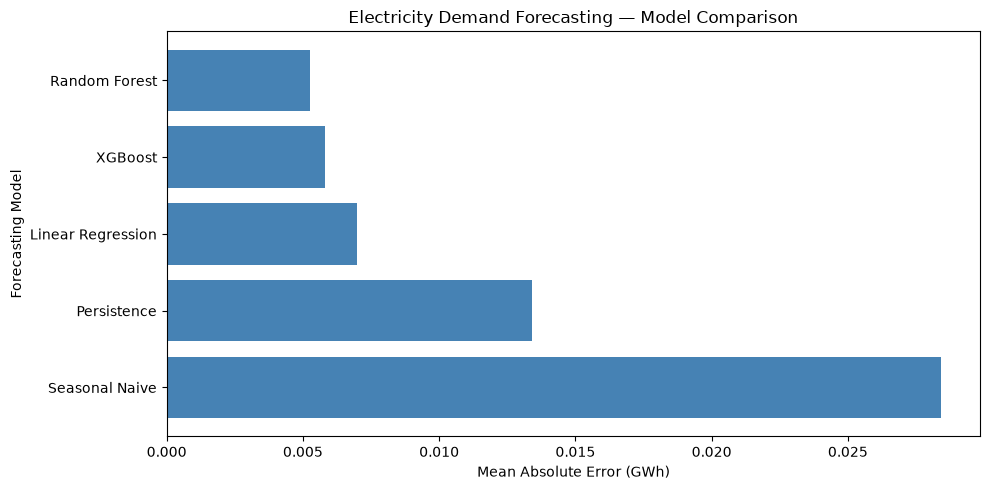

In [11]:
# Create model comparison table
model_results = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "Persistence",
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [
        baseline_mae,
        persistence_mae,
        linear_mae,
        rf_mae,
        xgb_mae
    ],
    "RMSE": [
        baseline_rmse,
        persistence_rmse,
        linear_rmse,
        rf_rmse,
        xgb_rmse
    ]
})

# Sort by prediction accuracy
model_results = model_results.sort_values("MAE")

# Plot
plt.figure(figsize=(10, 5))

plt.barh(
    model_results["Model"],
    model_results["MAE"],
    color="steelblue"
)

plt.xlabel("Mean Absolute Error (GWh)")
plt.ylabel("Forecasting Model")
plt.title("Electricity Demand Forecasting — Model Comparison")

plt.gca().invert_yaxis()
plt.tight_layout()

# Save for portfolio
plt.savefig(
    "../figures/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
from sklearn.metrics import mean_absolute_percentage_error

rf_mape = mean_absolute_percentage_error(
    y_test,
    rf_predictions
) * 100

print(f"Random Forest MAPE: {rf_mape:.2f}%")

Random Forest MAPE: 0.98%


In [13]:
import joblib
from pathlib import Path

# Create model directory
model_dir = Path.cwd().parent / "models"
model_dir.mkdir(exist_ok=True)

# Save trained Random Forest
joblib.dump(
    rf_model,
    model_dir / "random_forest_model.pkl"
)

# Save feature column names
joblib.dump(
    X_train.columns.tolist(),
    model_dir / "feature_columns.pkl"
)

print("Random Forest model saved successfully.")
print("Feature columns saved successfully.")

Random Forest model saved successfully.
Feature columns saved successfully.
